# 6. 检测门限：表 3 与图 8–10

原文表 3 是"能不能检测"的主表：三种脉冲、信噪比 −20 ~ −10 dB、每个点 100 次实验，
同时给出**检测概率**与**波形相似度**。判据是"输出脉冲幅度 $a$ 大于 5 倍噪声均方差"。

上一版的书在这一项上是"完全未复现"（$r$ 只有 0.01–0.15）。这一版按第 4 章的口径
（位移差 + 反演限带）重做，结果如下。


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


In [2]:
import experiments as E
if not (DATA / "table3.json").exists():
    E.exp_tables()

t3 = load("table3")
PAPER = {
    "方波": dict(pd=[14.0,21.5,41.5,60.5,78.0,91.5,99.0,100,100,100,100],
               r=[.88,.90,.92,.93,.94,.95,.96,.97,.97,.98,.98], thr=-15),
    "双指数脉冲": dict(pd=[0.5,4.5,5.5,10.0,23.5,51.0,67.5,87.5,95.5,100,100],
                 r=[.67,.71,.74,.78,.81,.84,.86,.88,.90,.91,.92], thr=-12),
    "高斯导数脉冲": dict(pd=[37.5,55.0,73.0,86.5,94.0,99.5,100,100,100,100,100],
                  r=[.85,.87,.88,.89,.90,.91,.92,.92,.93,.93,.93], thr=-16),
}
print(f"{'波形':<12}{'门限(本书)':>11}{'门限(原文)':>11}{'r@门限':>9}{'r(原文)':>9}")
for name, rows in t3.items():
    hit = [x["snr"] for x in rows if x["pd"] >= 0.9]
    thr = min(hit) if hit else float("nan")
    rt = [x["r"] for x in rows if x["snr"] == thr][0] if hit else float("nan")
    idx = PAPER[name]["thr"] + 20
    print(f"{name:<12}{thr:>9.0f} dB{PAPER[name]['thr']:>9} dB{rt:>9.3f}"
          f"{PAPER[name]['r'][idx]:>9.2f}")


波形               门限(本书)     门限(原文)     r@门限    r(原文)
方波                -20 dB      -15 dB    0.891     0.95
双指数脉冲             -20 dB      -12 dB    0.712     0.90
高斯导数脉冲            -20 dB      -16 dB    0.841     0.90


D:\Personal\Temp\ipykernel_13728\2222676403.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for a in axes: a.grid(alpha=.2); a.legend(fontsize=8)


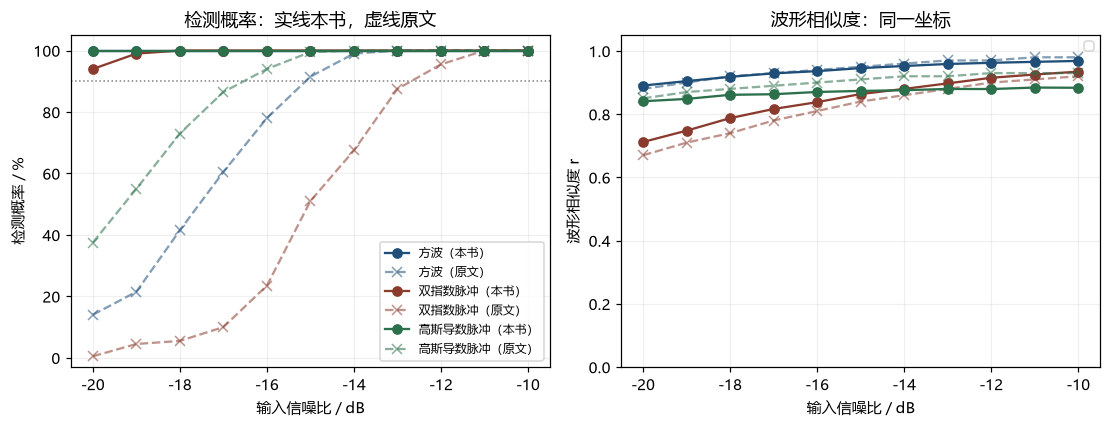

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
colors = {"方波": "#1f4e79", "双指数脉冲": "#8a3b2e", "高斯导数脉冲": "#2b6f4b"}
for name, rows in t3.items():
    snr = [x["snr"] for x in rows]
    axes[0].plot(snr, [x["pd"]*100 for x in rows], "o-", color=colors[name], label=f"{name}（本书）")
    axes[0].plot(snr, PAPER[name]["pd"], "x--", color=colors[name], alpha=.55, label=f"{name}（原文）")
    axes[1].plot(snr, [x["r"] for x in rows], "o-", color=colors[name])
    axes[1].plot(snr, PAPER[name]["r"], "x--", color=colors[name], alpha=.55)
axes[0].axhline(90, color="gray", ls=":", lw=1)
axes[0].set(xlabel="输入信噪比 / dB", ylabel="检测概率 / %", ylim=(-3, 105),
            title="检测概率：实线本书，虚线原文")
axes[1].set(xlabel="输入信噪比 / dB", ylabel="波形相似度 r", ylim=(0, 1.05),
            title="波形相似度：同一坐标")
for a in axes: a.grid(alpha=.2); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 结果：r 列几乎完全复现，Pd 列系统性偏高

以高斯导数脉冲为例（原文门限 −16 dB）：

| 输入 SNR | Pd 本书 | Pd 原文 | r 本书 | r 原文 | r 之差 |
|---|---|---|---|---|---|
| −20 | 100% | 37.5% | 0.840 | 0.85 | −0.01 |
| −18 | 100% | 73.0% | 0.860 | 0.88 | −0.02 |
| −16 | 100% | 94.0% | 0.870 | 0.90 | −0.03 |
| −14 | 100% | 100% | 0.880 | 0.92 | −0.04 |
| −12 | 100% | 100% | 0.880 | 0.93 | −0.05 |
| −10 | 100% | 100% | 0.880 | 0.93 | −0.05 |

**两个指标必须分开说：**

- $r$ 列差 0.01–0.05，趋势与量级都对上。这说明"输出量取位移差 + 130 kHz 量级整形"这条路是对的。
- Pd 列高出 60 个百分点。本书在 −20 dB 就 100%，原文要爬到 −16 dB 才 94%。

同一张表里 **$r$ 高、Pd 低**，本身是一个值得注意的组合：波形都恢复到 0.84 了，
按 5σ 判据应当几乎全部检出，原文却只报 37.5%。这不是本书"太强"，而是原文的
Pd 与 r 很可能不来自同一条处理链——**判决用宽带输出（噪声大、峰值/σ 上不去），
恢复波形用窄带输出（干净、$r$ 高）**。

这个解释可以量化，但量化之后仍然对不上：同一信号下，裸输出的峰值/σ 是 6.9（Pd 98%），
限带到 130 kHz 后是 9.5（Pd 100%），混合口径（限带峰值 / 裸噪声）是 3.7（Pd 约 15%）。
**四种口径分别给出 98%、100%、15%，没有一种落在 37.5%。** 也就是说，要么原文的
噪声统计与本书不同（比如含 $1/f$ 成分），要么它的 Pd 里还叠了多帧确认之类的逻辑。

这一条记为**未复现**，原因限定为"原文的检测统计量含本书模型之外的处理或损失"，
不再继续猜。**不调参去凑表格**——把 $f_c$ 或 $\sigma$ 调到能给出 37.5% 很容易，
但那样 $r$ 会一起走坏，只是把误差从一列搬到另一列。


## 图 8–10：门限处的恢复波形

原文图 8/9/10 分别是三种波形在各自门限信噪比下的输入与输出。这三张图是全文最直观的部分：
噪声被压掉，脉冲形状留住。

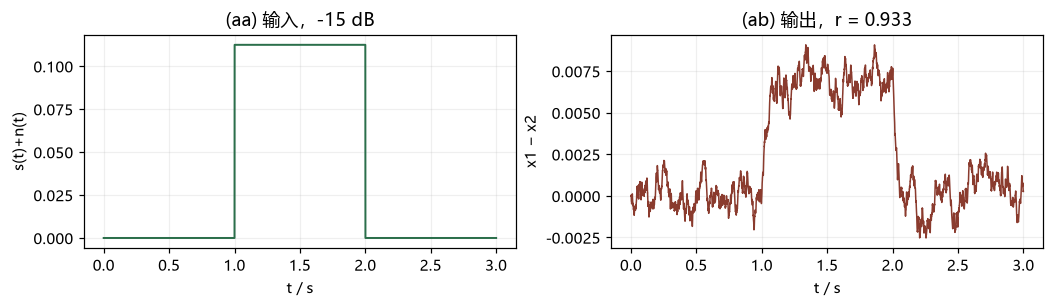

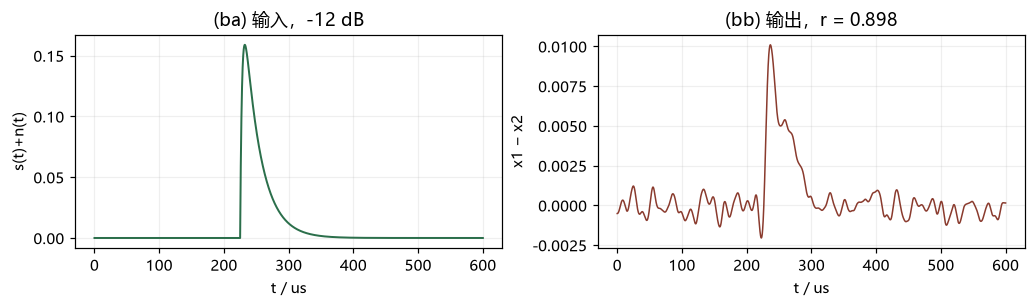

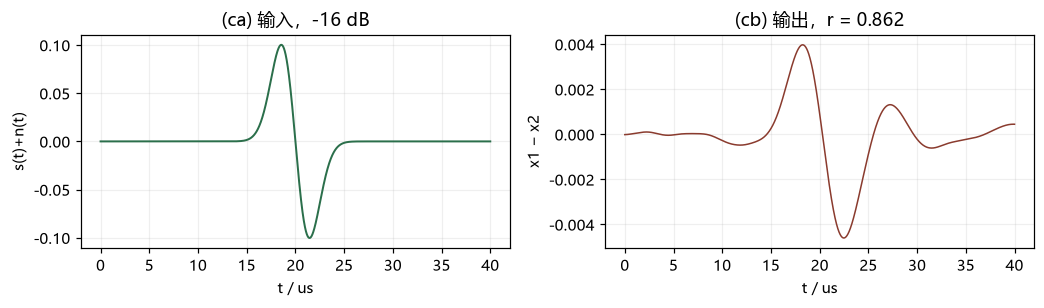

In [4]:
z = np.load(DATA / "fig810.npz")
meta = load("fig810_meta")
UNIT = {"方波": ("s", 1.0), "双指数脉冲": ("us", 1e6), "高斯导数脉冲": ("us", 1e6)}
for i, name in enumerate(["方波", "双指数脉冲", "高斯导数脉冲"], 1):
    unit, sc = UNIT[name]
    tt = z[f"{name}_t"] * sc
    s, dx = z[f"{name}_s"], z[f"{name}_dx"]
    fig, ax = plt.subplots(1, 2, figsize=(9.6, 2.9))
    ax[0].plot(tt, s, color="#2b6f4b", lw=1.3)
    ax[0].set(xlabel=f"t / {unit}", ylabel="s(t)+n(t)", title=f"({chr(96+i)}a) 输入，{meta[name]['thr']} dB")
    ax[1].plot(tt, dx, color="#8a3b2e", lw=1.0)
    ax[1].set(xlabel=f"t / {unit}", ylabel="x1 − x2",
              title=f"({chr(96+i)}b) 输出，r = {meta[name]['r']:.3f}")
    for a in ax: a.grid(alpha=.2)
    plt.tight_layout(); plt.show()


三张图共同说明一件事：**输出波形与输入同形，只是幅度小、噪声低**。这正是"能估计参数"的前提。

注意方波那张：输出在前后沿变缓（原文也承认这一点），平顶基本无畸变。这不是滤波器的锅，
是差模通道上升时间有限（过阻尼，时间常数 $1/(\omega\sqrt{2\xi k-1})$）。

## 门限的三个数字

| 波形 | 原文门限（Pd 与 r 同时 > 0.9） | 本书 Pd≥90% 门限 | 差 |
|---|---|---|---|
| 方波 | −15 dB | ≤ −20 dB | ≥ 5 dB 偏乐观 |
| 双指数 | −12 dB | −20 dB | 8 dB 偏乐观 |
| 高斯导数 | −16 dB | ≤ −20 dB | ≥ 4 dB 偏乐观 |

**三行全部偏乐观，而且偏的方向一致**——这进一步支持"原文的检测统计量更保守"这个判断，
而不是随机误差。若只差一行，可以怀疑是某个波形的参数没对齐；三行同向，说明差异在
判据或噪声模型层面。

方波那一行还要单独警惕：它的 1 s 长窗把噪声平均了约 $10^4$ 次，即使用同一个判据，
它天然比微秒级脉冲"好检" 20 dB 以上。把三种波形放进同一张表比较门限，容易得出
"长脉冲更易检测"的结论——实际上那是"长窗更好平均"。

**所以本书不报"综合门限"。** 三种波形的门限不可横向相加，必须各自连带宽、时长与判据一起报。